# Pipeline: YOLO Cắt Mặt Số Theo Đa Giác (Polygon Crop) -> CRNN & Tesseract Nhận Diện Chuỗi Số
Quy trình thử nghiệm End-to-End:
1. **YOLO-seg**: Phân đoạn đường viền đa giác (Polygon Mask) ôm sát vùng mặt số đồng hồ nước.
2. **Polygon Crop**: Cắt chính xác theo ranh giới đa giác, loại bỏ 100% vùng kim/vỏ ngoài thành nền trắng để chống nhiễu OCR.
3. **CRNN & Tesseract**: Nhận diện chuỗi ký tự từ ảnh cắt đa giác và đối chiếu kết quả.


In [38]:
import os, re, time, random, warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import cv2, torch, numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms
from ultralytics import YOLO
import pytesseract
import torch.nn as nn

%matplotlib inline
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.unicode_minus'] = False

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "ocr_evaluation" else Path.cwd()
IMAGES_DIR = PROJECT_ROOT / "data" / "DataAfterHandle" / "water_meters" / "images"

# 1. Nạp mô hình YOLO-seg
yolo_path = PROJECT_ROOT / "models_baseline/yolo11n-seg/water-meters/best.pt"
yolo_model = YOLO(str(yolo_path))

# 2. Định nghĩa & Nạp mô hình CRNN
class BidirectionalLSTM(nn.Module):
    def __init__(self, nIn, nHidden, nOut):
        super().__init__()
        self.rnn = nn.LSTM(nIn, nHidden, bidirectional=True)
        self.embedding = nn.Linear(nHidden * 2, nOut)
    def forward(self, x):
        rec, _ = self.rnn(x)
        T, b, h = rec.size()
        return self.embedding(rec.view(T * b, h)).view(T, b, -1)

class CRNN(nn.Module):
    def __init__(self, imgH=32, nc=1, nclass=11, nh=256):
        super().__init__()
        ks, ps, nm = [3, 3, 3, 3, 3, 3, 2], [1, 1, 1, 1, 1, 1, 0], [64, 128, 256, 256, 512, 512, 512]
        cnn = nn.Sequential()
        def convRelu(i, bn=False):
            nIn = nc if i == 0 else nm[i - 1]
            cnn.add_module(f'conv{i}', nn.Conv2d(nIn, nm[i], ks[i], 1, ps[i]))
            if bn: cnn.add_module(f'batchnorm{i}', nn.BatchNorm2d(nm[i]))
            cnn.add_module(f'relu{i}', nn.ReLU(True))
        convRelu(0); cnn.add_module('p0', nn.MaxPool2d(2, 2))
        convRelu(1); cnn.add_module('p1', nn.MaxPool2d(2, 2))
        convRelu(2, True); convRelu(3)
        cnn.add_module('p2', nn.MaxPool2d((2, 2), (2, 1), (0, 1)))
        convRelu(4, True); convRelu(5)
        cnn.add_module('p3', nn.MaxPool2d((2, 2), (2, 1), (0, 1)))
        convRelu(6, True)
        self.cnn = cnn
        self.rnn = nn.Sequential(BidirectionalLSTM(512, nh, nh), BidirectionalLSTM(nh, nh, nclass))
    def forward(self, x):
        c = self.cnn(x).squeeze(2).permute(2, 0, 1)
        return self.rnn(c)

crnn_path = PROJECT_ROOT / "models_baseline/crnn_after_aug/best_model.pth"
checkpoint = torch.load(crnn_path, map_location="cpu")
crnn_model = CRNN(32, 1, 11, 256)
crnn_model.load_state_dict(checkpoint["model_state_dict"])
crnn_model.eval()

crnn_transform = transforms.Compose([
    transforms.Grayscale(1),
    transforms.Resize((32, 100)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])


### 1. Hàm Cắt Đa Giác (Polygon Crop) & Pipeline OCR


In [39]:
def crop_by_polygon(img_bgr, poly):
    """Cắt chính xác theo đường bao đa giác, loại bỏ 100% phần vỏ/kim ngoài thành màu trắng."""
    h, w = img_bgr.shape[:2]
    mask = np.zeros((h, w), dtype=np.uint8)
    cv2.fillPoly(mask, [poly], 255)
    
    # Giữ phần trong đa giác, phần bên ngoài tô trắng (chống nhiễu cho OCR)
    masked = np.full_like(img_bgr, 255)
    masked[mask == 255] = img_bgr[mask == 255]
    
    # Cắt sát mép bao quanh đa giác
    x, y, bw, bh = cv2.boundingRect(poly)
    x1, y1 = max(0, x), max(0, y)
    x2, y2 = min(w, x + bw), min(h, y + bh)
    return masked[y1:y2, x1:x2]

def run_pipeline(img_path):
    img_bgr = cv2.imread(str(img_path))
    if img_bgr is None:
        return None
        
    # 1. YOLO phân đoạn đa giác
    t0_yolo = time.perf_counter()
    res = yolo_model(img_bgr, conf=0.25, verbose=False)
    yolo_ms = (time.perf_counter() - t0_yolo) * 1000
    
    masks = res[0].masks
    if masks is None or len(masks.xy) == 0:
        return None
        
    poly = masks.xy[0].astype(np.int32)
    crop_bgr = crop_by_polygon(img_bgr, poly)
    
    # 2. CRNN nhận diện chuỗi số từ ảnh cắt đa giác
    t0_crnn = time.perf_counter()
    tensor = crnn_transform(Image.fromarray(cv2.cvtColor(crop_bgr, cv2.COLOR_BGR2RGB))).unsqueeze(0)
    with torch.no_grad():
        out = crnn_model(tensor)
        pred = out.argmax(dim=2).permute(1, 0)[0]
        chars = [str(idx.item()) for i, idx in enumerate(pred) if idx.item() != 10 and (i == 0 or idx.item() != pred[i-1].item())]
        crnn_text = "".join(chars)
    crnn_ms = (time.perf_counter() - t0_crnn) * 1000
    
    # 3. Tesseract nhận diện chuỗi số
    t0_tess = time.perf_counter()
    gray_crop = cv2.cvtColor(crop_bgr, cv2.COLOR_BGR2GRAY)
    tess_raw = pytesseract.image_to_string(gray_crop, config='--psm 7 -c tessedit_char_whitelist=0123456789')
    tess_text = re.sub(r'[^0-9]', '', tess_raw)
    tess_ms = (time.perf_counter() - t0_tess) * 1000
    
    return {
        "image_name": img_path.name,
        "img_rgb": cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB),
        "crop_rgb": cv2.cvtColor(crop_bgr, cv2.COLOR_BGR2RGB),
        "poly": poly,
        "crnn_text": crnn_text,
        "crnn_ms": crnn_ms,
        "tess_text": tess_text,
        "tess_ms": tess_ms,
        "yolo_ms": yolo_ms
    }


### 2. Chạy Thử Nghiệm & Trực Quan Hóa Cắt Đa Giác (Polygon Crop)


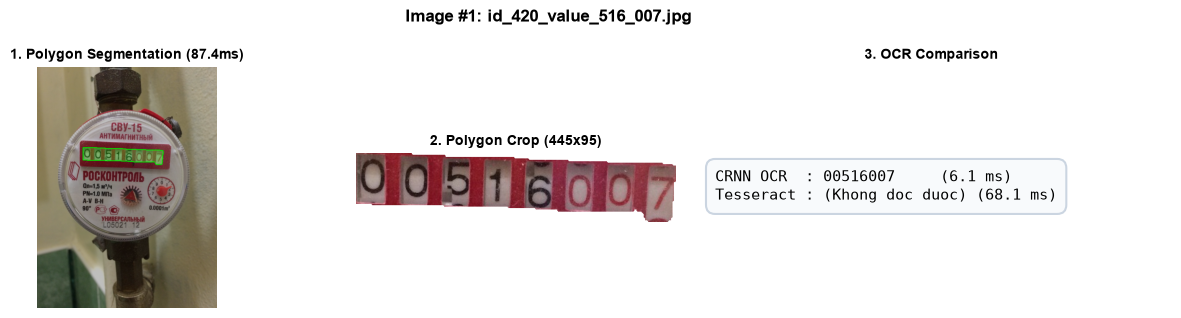

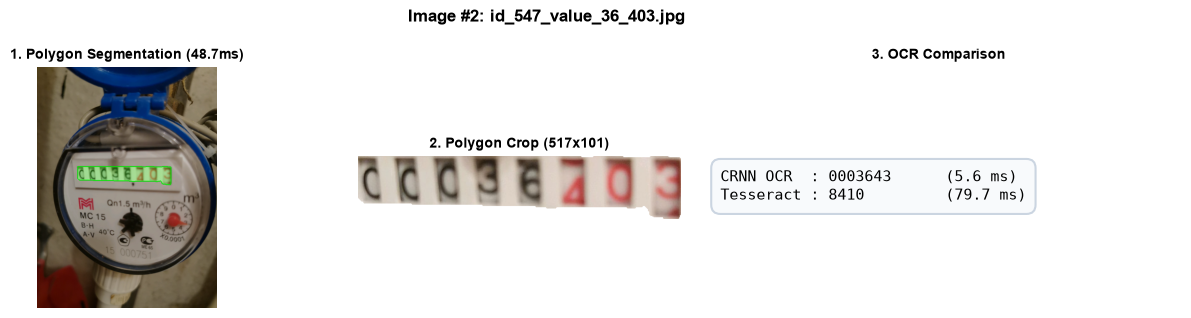

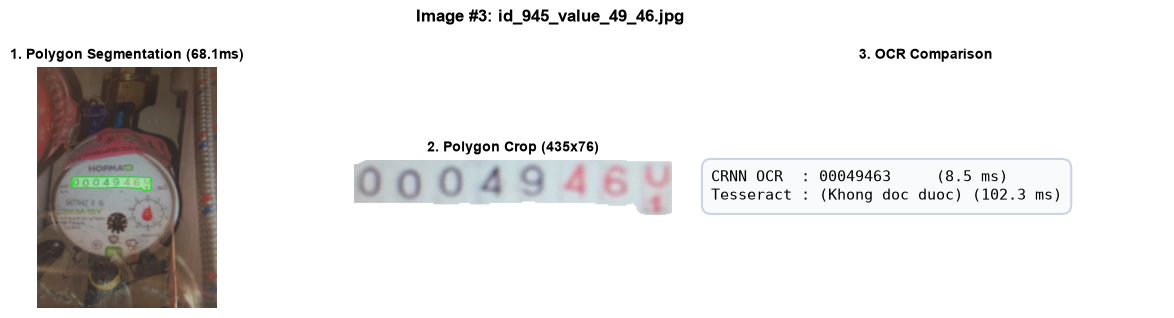

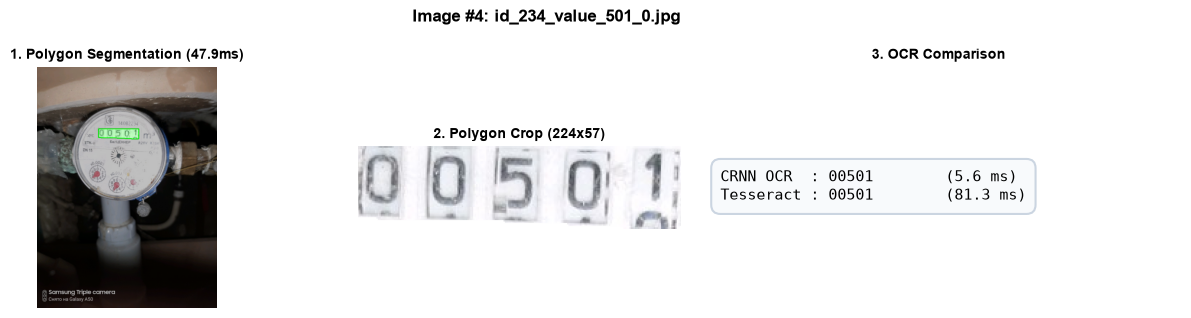

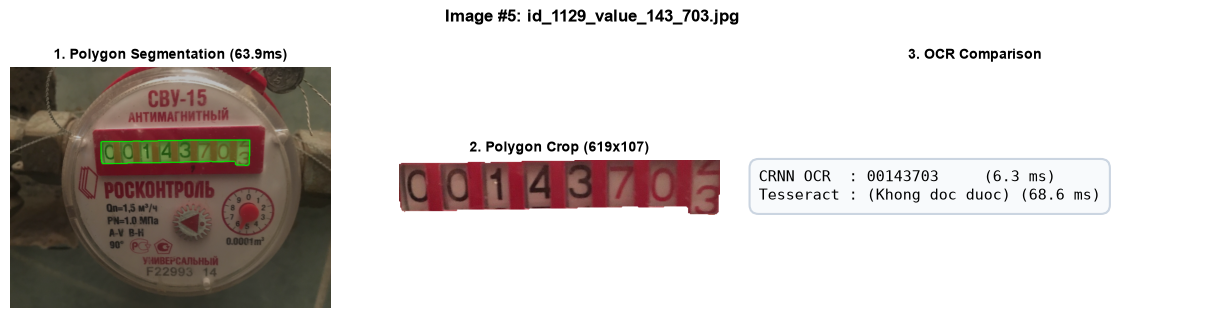

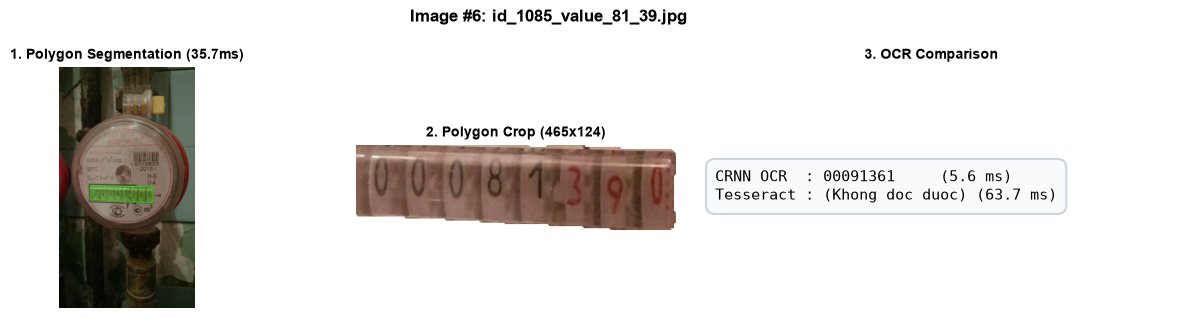

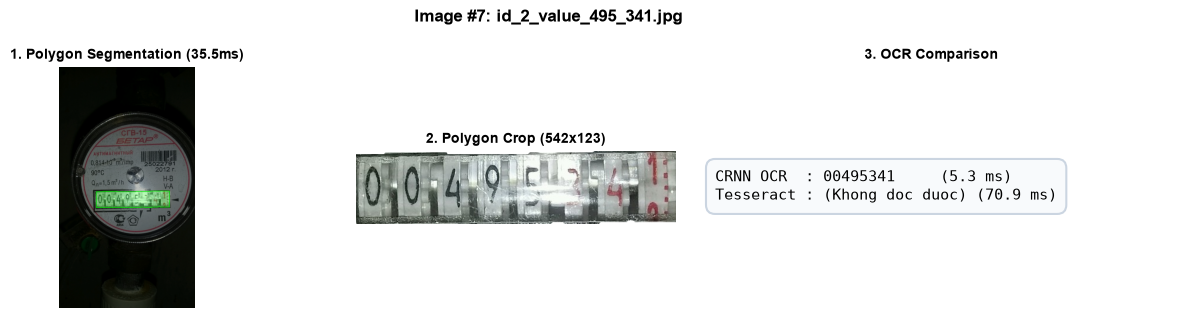

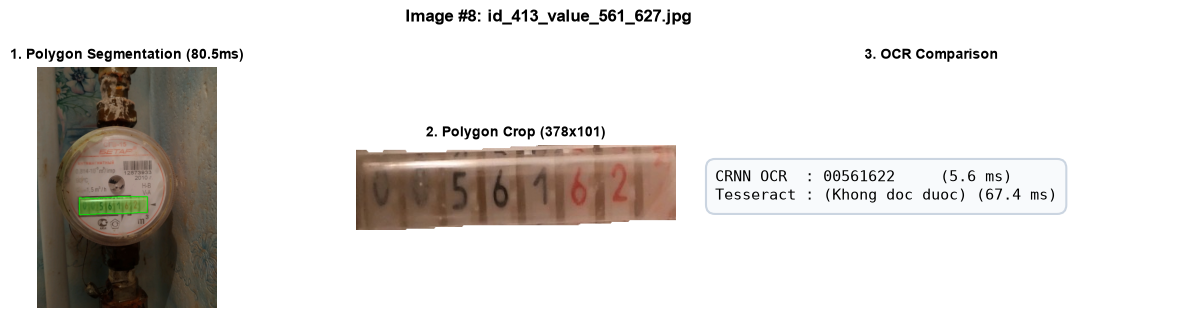

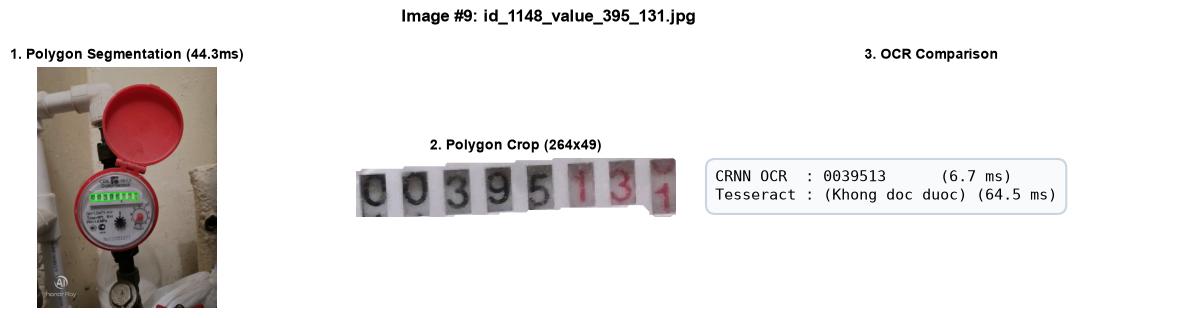

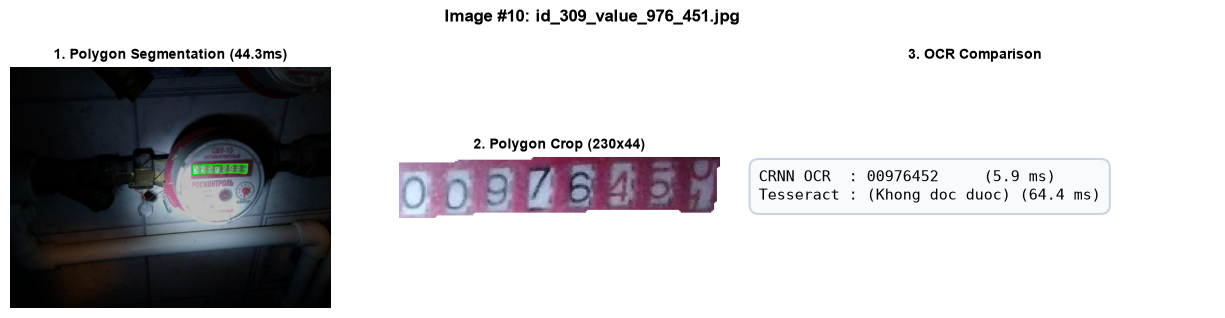

In [40]:
all_imgs = sorted(list(IMAGES_DIR.glob("*.jpg")))
test_imgs = random.sample(all_imgs, min(10, len(all_imgs)))

results_list = []

for idx, p in enumerate(test_imgs, 1):
    out = run_pipeline(p)
    if not out:
        continue
    results_list.append(out)
    
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), gridspec_kw={'width_ratios': [1.6, 1.2, 1.8]})
    
    # 1. Ảnh gốc + Vẽ đa giác Polygon Mask
    vis = out["img_rgb"].copy()
    poly = out["poly"]
    cv2.polylines(vis, [poly], isClosed=True, color=(0, 255, 0), thickness=3)
    overlay = np.zeros_like(vis)
    cv2.fillPoly(overlay, [poly], (0, 255, 0))
    cv2.addWeighted(overlay, 0.25, vis, 0.75, 0, vis)
    
    axes[0].imshow(vis)
    axes[0].set_title(f"1. Polygon Segmentation ({out['yolo_ms']:.1f}ms)", fontsize=10, fontweight="bold")
    axes[0].axis("off")
    
    # 2. Vùng cắt theo đa giác (Polygon Masked Crop)
    axes[1].imshow(out["crop_rgb"])
    axes[1].set_title(f"2. Polygon Crop ({out['crop_rgb'].shape[1]}x{out['crop_rgb'].shape[0]})", fontsize=10, fontweight="bold")
    axes[1].axis("off")
    
    # 3. Thẻ so sánh kết quả OCR
    axes[2].axis("off")
    crnn_display = out["crnn_text"] if out["crnn_text"] else "(Khong doc duoc)"
    tess_display = out["tess_text"] if out["tess_text"] else "(Khong doc duoc)"
    
    info_text = (
        f"CRNN OCR  : {crnn_display:<12} ({out['crnn_ms']:.1f} ms)\n"
        f"Tesseract : {tess_display:<12} ({out['tess_ms']:.1f} ms)"
    )
    axes[2].text(0.05, 0.45, info_text, fontsize=11, family='monospace',
                 bbox=dict(boxstyle="round,pad=0.6", facecolor="#F8FAFC", edgecolor="#CBD5E1", linewidth=1.5))
    axes[2].set_title("3. OCR Comparison", fontsize=10, fontweight="bold")
    
    plt.suptitle(f"Image #{idx}: {out['image_name']}", fontsize=12, fontweight="bold", y=0.98)
    plt.tight_layout()
    plt.show()


### 3. Bảng Tổng Hợp So Sánh Định Lượng & Biểu Đồ Tốc Độ


,Anh,CRNN,CRNN (ms),Tesseract,Tesseract (ms)
0,id_420_value_516_007.jpg,00516007,6.13,,68.15
1,id_547_value_36_403.jpg,0003643,5.61,8410,79.75
2,id_945_value_49_46.jpg,00049463,8.53,,102.31
3,id_234_value_501_0.jpg,00501,5.56,00501,81.32
4,id_1129_value_143_703.jpg,00143703,6.30,,68.60
5,id_1085_value_81_39.jpg,00091361,5.61,,63.74
6,id_2_value_495_341.jpg,00495341,5.27,,70.89
7,id_413_value_561_627.jpg,00561622,5.60,,67.40
8,id_1148_value_395_131.jpg,0039513,6.68,,64.47
9,id_309_value_976_451.jpg,00976452,5.94,,64.37


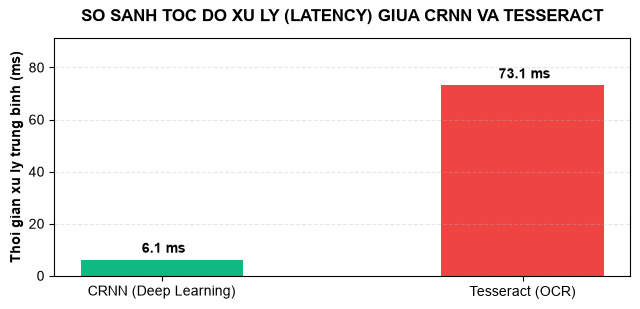

CRNN nhanh gap ~11.9 lan so voi Tesseract!


In [41]:
df_res = pd.DataFrame([{
    "Anh": r["image_name"],
    "CRNN": r["crnn_text"],
    "CRNN (ms)": round(r["crnn_ms"], 2),
    "Tesseract": r["tess_text"],
    "Tesseract (ms)": round(r["tess_ms"], 2)
} for r in results_list])

display(df_res)

# Biểu đồ so sánh thời gian xử lý (ms) giữa CRNN và Tesseract
avg_crnn = df_res["CRNN (ms)"].mean()
avg_tess = df_res["Tesseract (ms)"].mean()

plt.figure(figsize=(6.5, 3.2))
bars = plt.bar(["CRNN (Deep Learning)", "Tesseract (OCR)"], [avg_crnn, avg_tess], color=["#10B981", "#EF4444"], width=0.45)
plt.bar_label(bars, fmt=" %.1f ms", fontweight="bold", padding=3)
plt.ylabel("Thoi gian xu ly trung binh (ms)", fontweight="bold")
plt.title("SO SANH TOC DO XU LY (LATENCY) GIUA CRNN VA TESSERACT", fontweight="bold", pad=12)
plt.ylim(0, max(avg_crnn, avg_tess) * 1.25)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

print(f"CRNN nhanh gap ~{avg_tess / avg_crnn:.1f} lan so voi Tesseract!")
